# Hackathon 1, statistics.

This project illustrates the statistics part of the course LEPL1109. In the first part of the project, you will study the mortality observed in Belgium. In the second part of the project, you try to predict the electricity consumption in Belgium using climate variables.

## Report content

•	Grades are granted to the members whose names are in the Jupyter notebook. If your name doesn’t appear on the top of the notebook, you’ll get a 0, even though you are in a group on Moodle.

•	The jupyter notebook must be compiled with printed results and next submitted via moodle. The absence of compiled results (or non-printed values) leads to a lower grade.

•	Do not comment your results directly into cells of code. Use instead a Markdown cell. 

•	"Dry" code or results not followed by a minimum of analysis / comments will be penalized.


## Report submission

•	Deadline, see moodle website. Submission after the deadline will not be accepted.

•	To submit your report, go to the section “Hackathon” on Moodle and the subsection “Remise Hackathon 1”. You can upload your work there. Once you are sure that it is your final version, click the button “Envoyer le devoir”. It is important that you don’t forget to click on this button ! 

•	Reports that have not been uploaded through Moodle will not be corrected.


## Names and Noma of participants:

Part. 1: Berger Arthur  7067 2400

Part. 2: Collignon Robin  4958 2400

Part. 3: Doucet Noah 4035 2400 

Part. 4: Michiels Romain  3583 2400

Part. 5:

Part. 6:

# Mortality and climate

In this section, we analyze the relationship between mortality, age groups, and seasons in Belgium using publicly available data from Statbel (see https://statbel.fgov.be/en/about-statbel/what-we-do/visualisations/mortality). The dataset contains the number of deaths recorded over time, disaggregated by age group and observed across different seasons. The objective is to study temporal patterns in mortality and assess the role of seasonal effects. 

## 1. Basic statistics

**1.1)** Load the dataset mortality_climate.csv. Convert the variables *season* and *CD_AGEGROUP* into a categorical variable. 

In [22]:
# Code here
#installation de tous les modules utiles dans ce projet
%pip install pandas
%pip install matplotlib
%pip install numpy
%pip install scipy
%pip install statsmodels
import pandas as pd

#ouverture du fichier csv ainsi que catégorisation des colonnes "season" et "CD_AGEGROUP"
df = pd.read_csv("mortality_climate.csv", sep=',')
df["season"]=df["season"].astype("category")
df["CD_AGEGROUP"]=df["CD_AGEGROUP"].astype("category")


[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


**1.2)** Plot the evolution of the number of deaths (*MS_NUM_DEATH*) with respect to age group. What do you observe?

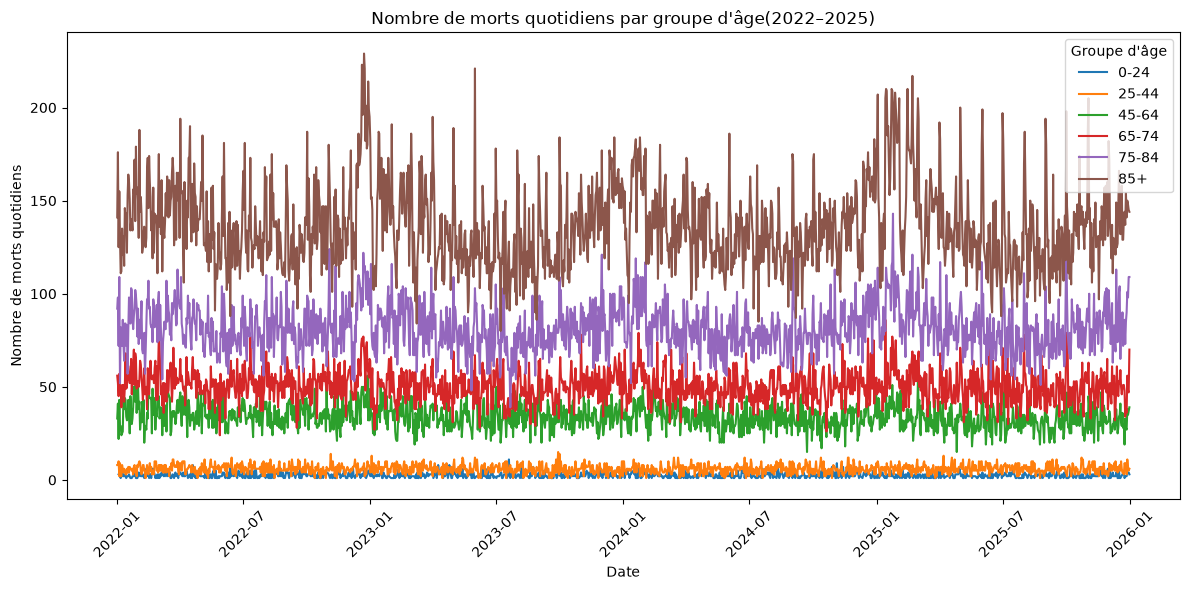

In [23]:
import matplotlib.pyplot as plt

# transformer la colonne "date" en type datetime
df["date"] = pd.to_datetime(df["date"])
#trie les différentes catégories d'age
ordre = ["0-24", "25-44", "45-64", "65-74", "75-84", "85+"]
#plot pour chaque catégorie le graphe du nombre de décès en fonction du temps
plt.figure(figsize=(12, 6))

for age in ordre:
    data = df[df["CD_AGEGROUP"] == age]
    data = data.sort_values("date")
    plt.plot(data["date"], data["MS_NUM_DEATH"], label=age)

plt.xlabel("Date")
plt.ylabel("Nombre de morts quotidiens")
plt.title("Nombre de morts quotidiens par groupe d'âge(2022–2025)")

plt.legend(title="Groupe d'âge", loc="upper right")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Comments:

Nous constatons différentes choses sur ce graphe. Premièrement, une augmentation du nombre de décès avec l'âge. En effet, la catégorie 85+ présente systématiquement un nombre de déces supérieur a toutes les autres catégories( aux alentours de 150 morts par jour). A l'inverse, les catégories 0-24 et 25-44 présentent un taux de décès relativement bas(entre 0 et 15 morts par jour). Ensuite, le nombre de décès par catégorie est stable au court du temps malgré certaines fluctuations fortement présente dans la catégorie d'age la plus élevée. Ces pics sont particulièrement élevés en janvier 2023 et 2025 amenant le nombre de décès par jour au dela de 215.
En conclusion, ce graphe met en évidence les fortes différences du nombre de décès en fonction de l'âge ainsi que la possibilité de fluctuation plus marquée.

**1.3)** Do a scatter plot of the number of deaths (*MS_NUM_DEATH*) by age group.

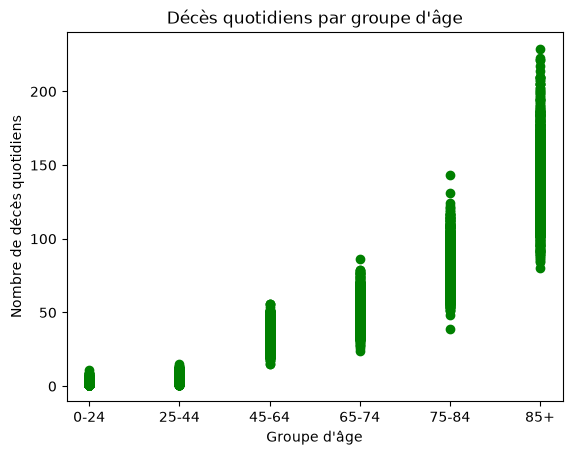

In [25]:
# Code here
#sélection des colonnes "CD_AGEGROUP" et "MS_NUM_DEATH" pour le scatter plot
age = df["CD_AGEGROUP"]
deaths = df["MS_NUM_DEATH"]
#imposition d'un ordre pour les catégories d'age
ordre = ["0-24", "25-44", "45-64", "65-74", "75-84", "85+"]
#tri des catégories d'age pour le scatter plot
df = df.sort_values("CD_AGEGROUP")
#plot
plt.scatter(age, deaths, color='g')
plt.xlabel("Groupe d'âge")
plt.ylabel("Nombre de décès quotidiens")
plt.title("Décès quotidiens par groupe d'âge")
plt.show()

Comments: 

Le graphique montre une augmentation de décès avec l'âge, surtout à partir de 65 ans. Les groupes d'âge plus jeunes présentent un nombre de décès relativement faible, tandis que le groupe des 85ans et plus enregistrent des valeurs bien plus élevées. On observe également une dispersion qui augmente avec l'age, indiquant une plus grande variabilité du nombre de décès par jour pour les personnes plus agées.

## 2. Fit of distributions

**2.1)** For the 45–64 age group and the winter season only, fit both a Poisson and a Negative Binomial distribution to the variable 'MS_NUM_DEATH' using a maximum likelihood approach. Plot histograms overlaid with the fitted probability mass functions. Compare the log-likelihoods and select the most appropriate distribution.

Log-vraisemblance de Poisson : -1219.3605439541718
Log-vraisemblance binomiale négative : -1208.0086907373143
n = 136.0 p = 0.7926986520805293


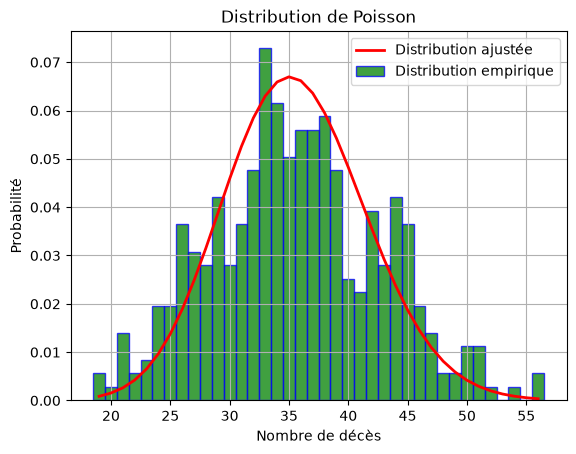

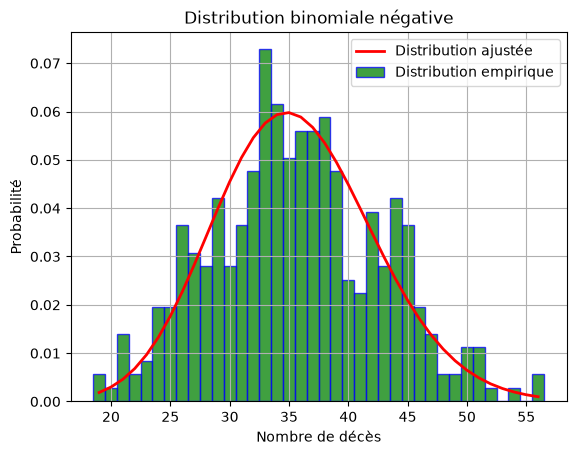

Log-vraisemblance de Poisson : -1219.3605439541718
Log-vraisemblance binomiale négative : -1208.0086907373143
La distribution binomiale négative possède la log-vraisemblance la plus élevée.


In [26]:
# Code ici

import scipy.stats as sc
from scipy.optimize import minimize
import numpy as np

# Sélectionner les données pour la tranche d'âge 45-64 ans et la saison hivernale
data = df[(df["season"].str.lower() == "winter") & (df["CD_AGEGROUP"] == "45-64")]

# Extraire les valeurs de la colonne "MS_NUM_DEATH" et supprimer les valeurs manquantes
datn = data["MS_NUM_DEATH"].dropna().values

# Distribution de Poisson : la méthode des moments avec une inconnue
# donne la moyenne empirique, qui est un estimateur sans biais.
lam = np.mean(datn)
ll_poisson = np.sum(sc.poisson.logpmf(datn, mu=lam))

print("Log-vraisemblance de Poisson :", ll_poisson)

# Distribution binomiale négative : utilisation de scipy afin de trouver
# directement la valeur des estimateurs
result = sc.fit(
    sc.nbinom,
    datn,
    bounds={"n": (1, 1000), "p": (0.001, 0.999), "loc": (0, 0)}
)

# Calcul de la log-vraisemblance pour la distribution binomiale négative
n, p, _ = result.params
ll_nb = -result.nllf()

print("Log-vraisemblance binomiale négative :", ll_nb)
print("n =", n, "p =", p)

# Tracer les graphiques des deux estimations par rapport à l'histogramme
# des données empiriques
x = np.arange(min(datn), max(datn) + 1)

fx_poisson = sc.poisson.pmf(x, mu=lam)
fx_nb = sc.nbinom.pmf(x, n, p)

plt.hist(datn, bins=np.arange(min(datn)-0.5, max(datn)+1.5),
         density=1, facecolor='g', alpha=0.75, edgecolor='b')
plt.plot(x, fx_poisson, 'r', lw=2)
plt.xlabel('Nombre de décès')
plt.ylabel('Probabilité')
plt.title('Distribution de Poisson')
plt.legend(['Distribution ajustée', 'Distribution empirique'])
plt.grid(True)
plt.show()

plt.hist(datn, bins=np.arange(min(datn)-0.5, max(datn)+1.5),
         density=1, facecolor='g', alpha=0.75, edgecolor='b')
plt.plot(x, fx_nb, 'r', lw=2)
plt.xlabel('Nombre de décès')
plt.ylabel('Probabilité')
plt.title('Distribution binomiale négative')
plt.legend(['Distribution ajustée', 'Distribution empirique'])
plt.grid(True)
plt.show()

# Comparaison des log-vraisemblances
print("Log-vraisemblance de Poisson :", ll_poisson)
print("Log-vraisemblance binomiale négative :", ll_nb)

if ll_poisson > ll_nb:
    print("La distribution de Poisson possède la log-vraisemblance la plus élevée.")
else:
    print("La distribution binomiale négative possède la log-vraisemblance la plus élevée.")



Comments: 

On constate que la binomiale négative donne une approximation plus précise car il a une vraissemblance plus élevée que celle par la distribution de poisson. En effet, on constate que la binomiale négative correspond mieux à la répartition expérimentale. Cela est fortement visible pour les valeurs extrêmes.

# 3. Regression

We now aim to assess whether seasonality has an impact on the number of deaths. We consider the following linear model:
$$\log(Y_i) = \beta_0 + \beta_1 X^S_{i1} + \cdots + \beta_3 X^S_{i3} + \beta_4 X^{age}_{i1} + \cdots + \beta_8 X^{age}_{i5}  + \varepsilon_i.$$

where $Y_i$ denotes the number of deaths, $X^S_{ij}$ are dummy variables representing the different seasons, $X^{age}_{ij}$ are dummy variables representing the different age groups, and $\varepsilon_i \sim N(0, \sigma^2)$. 

**3.1)** Why is it more appropriate to use a linear regression on $\log(Y)$ rather than directly on $Y$?

Comments: 

Le logarithme permet de réduire la dispersion des données et de limiter l'influence des valeurs élevées. Il permet également d'interpréter les coefficients de régression en termes de variations relatives (pourcentages) plutôt qu'absolues.

**3.2)** Perform a linear regression of the number of deaths on the seasonal and group age covariates. Use the `OLS` function from the *statsmodels* package. Make sure to convert the variable *season* and *CD_AGEGROUP* into dummy variables before fitting the model.

Does seasonality have a significant impact on mortality? Is the mortality similar for each age group? 

In [8]:
# Code here
import statsmodels.api as sm

# On transforme en variables indicatrices
season_dum = pd.get_dummies(df["season"], drop_first=True, dtype=int)
agegroup_dum = pd.get_dummies(df["CD_AGEGROUP"], drop_first=True, dtype=int)
if(( df["MS_NUM_DEATH"]<=0).all()):print("Attention : certaines valeurs de MS_NUM_DEATH sont nulles ou négatives, ce qui peut poser problème pour la transformation logarithmique.")
Y = np.log(df["MS_NUM_DEATH"])

X = pd.concat([season_dum, agegroup_dum], axis=1)
# On ajoute une constante (pour beta0)
Xm = sm.add_constant(X)

# Utilisation du modèle OLS comme demandé + fitting 
results = sm.OLS(Y, Xm).fit()

# Affichage des résultats
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:           MS_NUM_DEATH   R-squared:                       0.951
Model:                            OLS   Adj. R-squared:                  0.951
Method:                 Least Squares   F-statistic:                 2.110e+04
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:41:55   Log-Likelihood:                -2628.0
No. Observations:                8625   AIC:                             5274.
Df Residuals:                    8616   BIC:                             5338.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.7921      0.011     72.499      0.0

Comments: 

Premièrement, on remarque que la qualité globale de la régression est très bonne. En effet, le coefficient de détermination (R^2=0,951) indique que 95,1 % de la variabilité de (log(Y)) est expliquée par l'âge et les saisons. De plus, la p-value associée au test F est quasiment nulle, ce qui permet de rejeter l'hypothèse selon laquelle tous les coefficients des variables explicatives sont nuls.

Ensuite, la régression montre que l'âge est associé à une forte augmentation du nombre de décès. À l'inverse, l'effet des saisons est nettement plus faible. En effet, les coefficients associés aux groupes d'âge sont beaucoup plus élevés en valeur absolue que ceux des saisons. On constate néanmoins que les effets de l'été et de l'hiver sont statistiquement significatifs (p<0,05), contrairement à celui du printemps.

## 4. Hypothesis test 

We now investigate whether mortality decreases over time by comparing mortality in summer in 2022 and 2025. To this end, we aim to perform the following hypothesis test:

$$
H_0 : \mu_{2022} = \mu_{2025},
$$

$$
H_1 : \mu_{2022} \neq \mu_{2025}.
$$

**4.1)** Create two subsets of the original dataset corresponding to the years 2022 and 2025, respectively.

In [9]:
#choix des colonnes
df_2022 = df[(df["date"].dt.year == 2022)]
df_2025 = df[(df["date"].dt.year == 2025)]


**4.2)** For the 85+ age group, perform a Student’s t-test to compare mortality between 2022 and 2025 **in summer**. Check whether the assumptions required to apply this test are satisfied.

In [10]:
import scipy.stats as sc
import numpy as np
#sélection des données pour l'âge 85+ et la saison été
mortality_22 = df_2022[(df_2022["CD_AGEGROUP"].eq("85+")) & (df_2022["season"].eq("summer"))]["MS_NUM_DEATH"].to_numpy()
mortality_25 = df_2025[(df_2025["CD_AGEGROUP"].eq("85+")) & (df_2025["season"].eq("summer"))]["MS_NUM_DEATH"].to_numpy()
#calcul de la taille des échantillons, de la moyenne et de l'écart type pour chaque année
n22 = len(mortality_22)
n25 = len(mortality_25)
Xb22 = np.mean(mortality_22)
Xb25 = np.mean(mortality_25)
S22 = np.std(mortality_22, ddof=1)
S25 = np.std(mortality_25, ddof=1)
#calcul de la variance combinée et du test t observé
Spool = np.sqrt(((n22-1)*(S22**2) + ((n25-1)*(S25**2))) / (n22 + n25 - 2))
Tx    = (Xb22 - Xb25)/(Spool*np.sqrt(1/n22+1/n25))

#H0 et calcul de la p-value
pval = 2*sc.t.cdf(-np.abs(Tx),df=n22+n25-2)
print("p")
print([pval])
if(pval > 0.05): print("On ne peut pas rejetter H0 car il n'ya pas de différence statistiquement significative entre les deux moyennes")
else : print("On peut rejetter H0 car il y a une différence statistiquement significative entre les deux moyennes")

#H1 et calcul de l'intervalle de confiance
alpha = 0.05
t_l   = sc.t.ppf(q=alpha/2, df=n22+n25-2)
t_u   = sc.t.ppf(q=1-alpha/2, df=n22+n25-2)

print("t" + " t_lower" + " t_upper")
print([Tx, t_l, t_u])

#confidence interval alpha = 0.05
diff = Xb22 - Xb25
term = t_u*Spool*np.sqrt(1/n22+1/n25)
print("différence des moyennes (Xb2022 - Xb2025) = ", diff)
print("intervale de confiance (a=0.05)")
print([diff - term, diff + term])

p
[np.float64(0.042505762212459004)]
On peut rejetter H0 car il y a une différence statistiquement significative entre les deux moyennes
t t_lower t_upper
[np.float64(2.0425744211253742), np.float64(-1.972800113995442), np.float64(1.9728001139954416)]
différence des moyennes (Xb2022 - Xb2025) =  5.9787234042553195
intervale de confiance (a=0.05)
[np.float64(0.20423308876236046), np.float64(11.753213719748278)]


Comments:

On a bien une indépendance des X et Y, on considère que chaque mort est indépendante l'une de l'autre. Néanmoins, la courbe ne suit pas clairement une normale comme le veut l'hypothèse comme on peut le voir aux exercices 1.2, 1.3. Comme la p-valeur est en dessous de 0,05 on a que l'hypothèse H1 est la bonne, donc mu1 différent de mu2. On voit au print que la moyenne est plus grande en 2022 qu'en 2025. Elle descend bien avec le temps. L'intervalle de confiance à 95% est entre 0.2 et 11.75 décès par jour de différence. Comme cet intervalle ne contient pas 0, on reconfirme bien la statistique plus élevée en 2022 qu'en 2025. A prendre avec des pincettes au vu des hypothèses pas pleinement vérifiées.

**4.3)** Explain what the Wilcoxon test is. Why could it be relevant in our setting?

Comments: 

Le test de Wilcoxon est un test statistique qui compare deux variables aléatoires I.I.D sans avoir le besoin comme le Student's t d'une normalité de la distribution. Ce test est moins demandant en hypothèses. Il compare la position des données dans l'ordre des décès à la place des moyennes (student's t). Ce test est un bon test complémentaire pour comparer les deux années, sous des hypothèses mieux satisfaites.

**4.4)** For the 85+ age group, perform a Wilcoxon test to compare mortality between 2022 and 2025 **in summer**. What do you conclude?

In [12]:
#calcul de la statistique U de Wilcoxon et de la p-value associée
U_wilcoxon, pval_wilcoxon = sc.mannwhitneyu(
    mortality_22,
    mortality_25,
    alternative="two-sided"
)
#print des résultats
print("Statistique U :", U_wilcoxon)
print("p-value :", pval_wilcoxon)

if pval < 0.05:
    print("On rejette H0 : les distributions diffèrent significativement.")
else:
    print("On ne rejette pas H0 : différence non significative.")

Statistique U : 5555.0
p-value : 0.0023094915928322237
On rejette H0 : les distributions diffèrent significativement.


Comments:

Le test de Wilcoxon renforce la validité de notre test précédent car la p-valeur = 0.0023 est bien en dessous de la valeur significative 0.05.

**4.5)** Perform the Wilcoxon test but now for the 25–44 age group and the **summer**. What do you conclude in this case?

In [13]:
#choix des colonnes
mortality_25_44_summer_22 = df_2022[(df_2022["CD_AGEGROUP"].eq("25-44")) & (df_2022["season"].eq("summer"))]["MS_NUM_DEATH"].to_numpy()
mortality_25_44_summer_25 = df_2025[(df_2025["CD_AGEGROUP"].eq("25-44")) & (df_2025["season"].eq("summer"))]["MS_NUM_DEATH"].to_numpy()
#exécution de la statistique U de Wilcoxon et calcul de la p-value
U_wilcoxon, pval_wilcoxon = sc.mannwhitneyu(mortality_25_44_summer_22, mortality_25_44_summer_25)
print("U " + "p_val")
print([U_wilcoxon, pval_wilcoxon])

#H0
if(pval_wilcoxon > 0.05): print("H0 s'applique, il n'y a pas assez de différence")

U p_val
[np.float64(4651.5), np.float64(0.5285373504458225)]
H0 s'applique, il n'y a pas assez de différence


Comments: 

Le test donne une p-value de 0,529, supérieure au seuil de significativité de 0,05. On ne rejette donc pas l'hypothèse nulle. Les données ne fournissent pas de preuve statistiquement significative d'une différence entre les distributions des décès quotidiens des 25–44 ans durant les étés 2022 et 2025.

# Electricity Consumption and Climate

In this section, we aim to predict electricity consumption using past consumption values and climatic variables. We rely on data provided by ELIA (see https://opendata.elia.be/explore/dataset/ods003/information/?sort=datetime), which records total electricity consumption in Belgium at a 15-minute frequency, and meteorological data from the Royal Meteorological Institute (IRM) (see https://www.meteo.be/fr/services/donnees), which provides daily average temperature observations over Belgium.

The goal is to build a predictive model for electricity demand based on its recent history and weather conditions. From a practical perspective, such forecasting is highly relevant for energy providers and grid operators, as accurately anticipating electricity demand one week ahead helps optimize production planning, ensure grid stability, and reduce operational costs.

## 5. Forecasting 

The goal is to predict electricity consumption at time $t$ using its past values and climate features. Let $Y_t$ denote electricity consumption at time $t$. We consider the following regression model:

$$Y_t = \beta_0 + \beta_1 Y_{t-7Days} + \beta_2 \bar{T}_{t-7Days} + \beta_3 \bar{T}_{t-7Days}^2 + \varepsilon_t,$$

where $Y_{t-7Days}$ denotes electricity consumption observed 7 days earlier, $\bar{T}_{t-7Days}$ is the average temperature observed 7 days earlier$^1$, and $\varepsilon_t \sim \mathcal{N}(0,\sigma^2)$ is an error term.

$^1$ The average temperature is measured at a daily frequency; therefore, $\bar{T}_{t-7Days}$ is constant for all time points $t$ within the same day.

**5.1)** Load the dataset *electricity_climate.csv* and construct the dataset required to perform the regression.

**Warning:** the data are observed at 15-minute intervals.

To build the regression dataset, each row must contain:
- electricity consumption at time $t$: $Y_t$,
- electricity consumption at time $t - 7$ days: $Y_{t-7Days}$,
- temperature at time $t - 7$ days: $\bar{T}_{t-7Days}$,
- the squared temperature at time $t - 7$ days: $\bar{T}_{t-7Days}^2$.

In [14]:
# Code here 
#choix des colonnes
df=pd.read_csv("electricity_climate.csv", sep=',')
df["Y"]=df["Consumption"]
df["Y_lag7"]=df["Consumption"].shift(672)
df["T_lag7"]=df["temp_avg"].shift(672)
df["T_lag7_squared"]=df["temp_avg_sq"].shift(672)
#mise en forme des données pour le modèle
data=df[["Y","Y_lag7","T_lag7","T_lag7_squared"]].dropna()

**5.2)** Split the dataset into a training set (first 75%) and a test set (last 25%).  Use the `OLS` function from the *statsmodels* package to fit linear regression model using only $Y_{t-7Days}$ as explanatory variable.

Analyze the regression output, discuss the statistical significance and performance of the model.

In [15]:
# Code here 
import statsmodels.api as sm
#séparation des données en train et test
n = int(len(data)*0.75)
train = data.iloc[:n]
test = data.iloc[n:]
#création de la matrice X et du vecteur Y pour la régression
X = sm.add_constant(train["Y_lag7"])
Y = train["Y"]

# Régression
model = sm.OLS(Y, X).fit()
print(model.summary())

# Prédictions
X_test = sm.add_constant(test["Y_lag7"])
Y_pred = model.predict(X_test)


                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.688
Model:                            OLS   Adj. R-squared:                  0.688
Method:                 Least Squares   F-statistic:                 6.492e+05
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:43:18   Log-Likelihood:            -2.3942e+06
No. Observations:              294694   AIC:                         4.788e+06
Df Residuals:                  294692   BIC:                         4.788e+06
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1368.5951      8.738    156.630      0.0

Comments:

La consommation électrique observée 7 jours auparavant est positivement associée à la consommation actuelle, avec un coefficient de 0,8342, statistiquement significatif (p-value < 0,05).

Le modèle explique 68,8 % de la variabilité de la consommation électrique (R^2=0,688), ce qui indique un ajustement relativement satisfaisant.

**5.3)** Repeat the regression by including the climate variables in the model.

Are the climate variables statistically significant in explaining electricity consumption 7 days ahead?

In [16]:
# Code here
import statsmodels.api as sm
#séparation des données en train et test
n = int(len(data)*0.75)
train2 = data.iloc[:n]
test2 = data.iloc[n:]
#création de la matrice X et du vecteur Y pour la régression avec les variables supplémentaires
X2 = sm.add_constant(train2[["Y_lag7", "T_lag7", "T_lag7_squared"]])
Y2 = train2["Y"]
# Régression
model2 = sm.OLS(Y2, X2).fit()
print(model2.summary())
# Prédictions
X_test2 = sm.add_constant(test2[["Y_lag7", "T_lag7", "T_lag7_squared"]])
Y_pred2 = model2.predict(X_test2)


                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.689
Model:                            OLS   Adj. R-squared:                  0.689
Method:                 Least Squares   F-statistic:                 2.179e+05
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:43:37   Log-Likelihood:            -2.3935e+06
No. Observations:              294694   AIC:                         4.787e+06
Df Residuals:                  294690   BIC:                         4.787e+06
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const           1289.2824     12.241    105.

Comments: 

On observe une très légère amélioration de la qualité de l'ajustement, puisque le R² passe de 0,688 à 0,689. L'ajout des variables climatiques n'apporte donc qu'une contribution marginale à l'explication de la variabilité de la consommation électrique.

Les coefficients associés à la température et à son carré sont statistiquement significatifs (p-value inférieure à 0,05). Leur signe respectivement positif et négatif indique une relation quadratique concave entre la température et la consommation électrique.

Malgré cette significativité statistique, l'amélioration du pouvoir explicatif reste très limitée.

**5.4)** Compute the MAE and RMSE on the test set for both models: with and without climate variables.

Does the inclusion of climate variables improve the predictive performance of the model?

In [18]:
# Code here 
#calcul du MAE et du RMSE pour les deux modèles
mae = np.abs(test["Y"] - Y_pred).mean()
rmse = np.sqrt(((test["Y"] - Y_pred)**2).mean())

mae2 = np.abs(test2["Y"] - Y_pred2).mean()
rmse2 = np.sqrt(((test2["Y"] - Y_pred2)**2).mean())

print("MAE model 1:", mae)
print("RMSE model 1:", rmse)
print("MAE model 2:", mae2)
print("RMSE model 2:", rmse2)

MAE model 1: 928.0686218871704
RMSE model 1: 1258.5706657773337
MAE model 2: 924.7252365298143
RMSE model 2: 1256.0503934128733


Comments: 

On constate que l'ajout de la température améliore très légèrement les performances prédictives du modèle. En effet, la MAE diminue de 928,07 à 924,73, soit une réduction d'environ 0,36 %. De même, la MSE subit une diminution d'environ 0,20 %.

On peut donc conclure que l'ajout des variables climatiques apporte une amélioration marginale des prédictions, ce qui est cohérent avec la très faible augmentation du R² observée précédemment.

**5.5)** For the model including climate variables, plot the predicted electricity consumption versus the true consumption on the test set. Then, produce a second plot focusing only on the first 7 days of the test set.

<Figure size 1200x500 with 0 Axes>

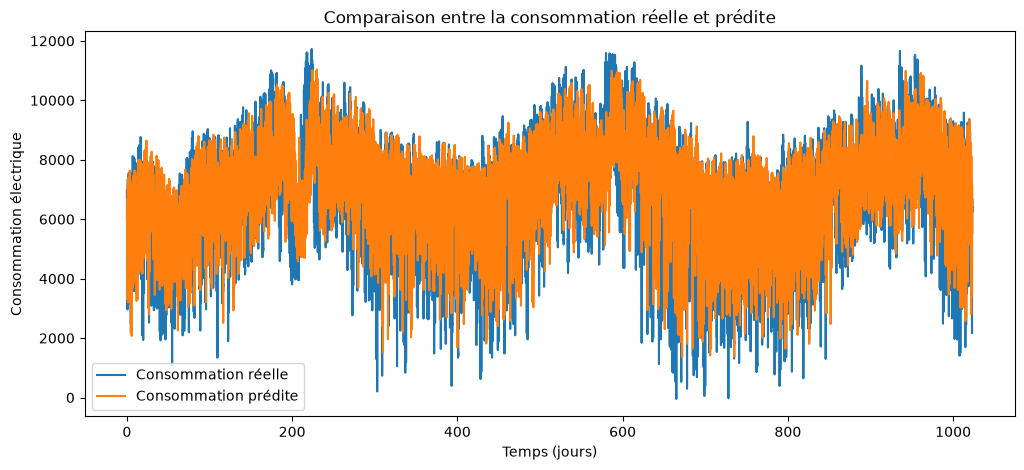

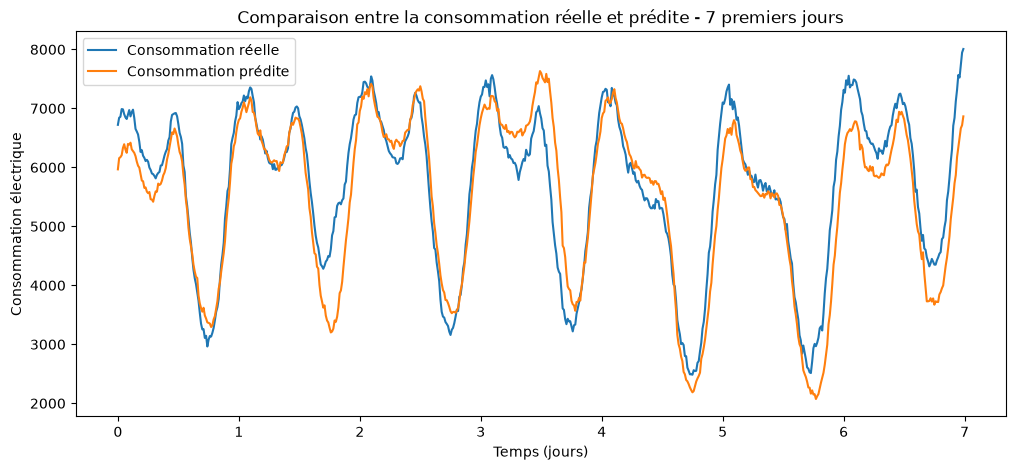

In [20]:
# Code here 
#plot du graphique pour comparer les valeurs réelles et prédites pour le modèle 2
plt.figure(figsize=(12, 5))

time = np.arange(len(test["Y"])) / 96

plt.figure(figsize=(12, 5))

plt.plot(time, test["Y"].values, label="Consommation réelle")
plt.plot(time, Y_pred2.values, label="Consommation prédite")

plt.xlabel("Temps (jours)")
plt.ylabel("Consommation électrique")
plt.title("Comparaison entre la consommation réelle et prédite")
plt.legend()
plt.show()

#polt du même graphique mais pour les 7 premiers jours
plt.figure(figsize=(12, 5))

plt.plot(time[:672],test["Y"].values[:672], label="Consommation réelle")
plt.plot(time[:672],Y_pred2.values[:672], label="Consommation prédite")

plt.xlabel("Temps (jours)")
plt.ylabel("Consommation électrique")
plt.title("Comparaison entre la consommation réelle et prédite - 7 premiers jours")
plt.legend()
plt.show()

Comments:

Le modèle suit correctement la tendance générale de consommation ainsi que les variations journalières. Cependant, il sous-estime ou surestime certains pics et creux, avec des prédictions plus lissées que les valeurs réelles.

Il reproduit donc assez bien les variations globales, mais reste moins précis pour les fluctuations ponctuelles.